<a href="https://colab.research.google.com/github/ivetoak/hello-world/blob/main/Pontia_ModuloViz_Caso1_EligiendoTurno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Pontia Tech - Master Data Analytics - Visualización de Datos con Python**

***
Datos del alumno (Nombre y Apellidos): Ivette Fernàndez

Fecha: 19/01/2026
***

<span style="font-size: 30pt; font-weight: bold; color: #0098cd;">Eligiendo Turno de Trabajo en la Cafeteria</span>

<span style="font-size: 15pt; font-weight: bold; color: #0098cd;">Actividad Complementaria</span>



**Objetivos**

Resuelve las preguntas realizando visualizaciones en matplotlib o seaborn.

**Enunciado**

Somos estudiantes de un magnífico máster de Data Analyst y para sacar unos ahorros hasta conseguir nuestro trabajo deseado estamos trabajando en un restaurante de comidas.

Nos han dado la opción de elegir turno, y como parte de nuestro sueldo se basa en propinas vamos a utilizar todas las herramientas de visualización que conocemos para elegir el mejor turno, ya que hemos podido acceder a la base de datos del local.

Responde las preguntas y argumenta.

In [2]:
# libraries
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [ ]:
# comando a utilizar si usamos Jupyter notebook (local)
# para asegurar que las graficas aparezcan debajo de cada celda
%matplotlib inline

**0. Carga el dataset de SEABORN de "TIPS"**

In [3]:
df = sns.load_dataset("tips") #llamamos a seaborn i al dataset base que tiene seaborn que tienen que trabajar.
df.head(3)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3


In [5]:
# Mini EDA
df.dtypes

,0
total_bill,float64
tip,float64
sex,category
smoker,category
day,category
time,category
size,int64


In [6]:
df.shape

(244, 7)

In [7]:
df.isnull().sum()

,0
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


## Preguntas

**1. ¿Qué día de trabajo es el favorito de los clientes?**

1. Preparación del dato
2. Visualización básica (matplotlib)
3. Customización

In [13]:
df_1 = df['day'].value_counts().reset_index().sort_values(by='day')
df_1

,day,count
2,Thur,62
3,Fri,19
0,Sat,87
1,Sun,76


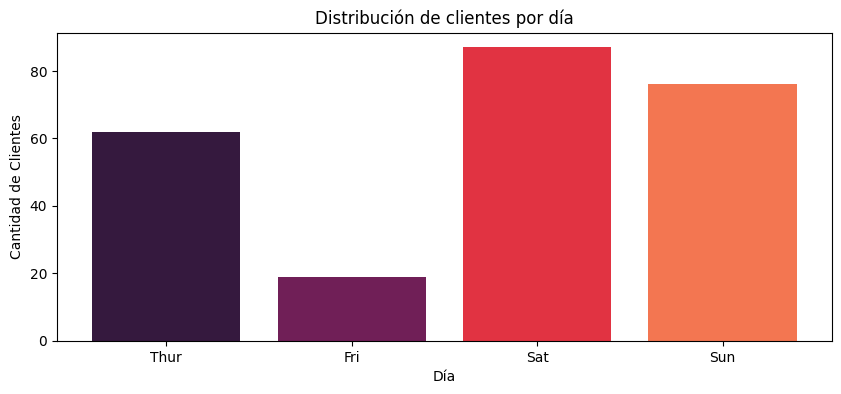

In [24]:
# BAR PLOT

plt.figure(figsize=(10,4))
plt.bar(x='day', height='count', data=df_1, color = ['#35193e', '#701f57', '#e13342', '#f37651']) #con colores manuales o escala hexadecimal
plt.title('Distribución de clientes por día')
plt.xlabel('Día')
plt.ylabel('Cantidad de Clientes')
plt.show()

Respuesta: La cantidad de clientes que más nos visita son los sábados

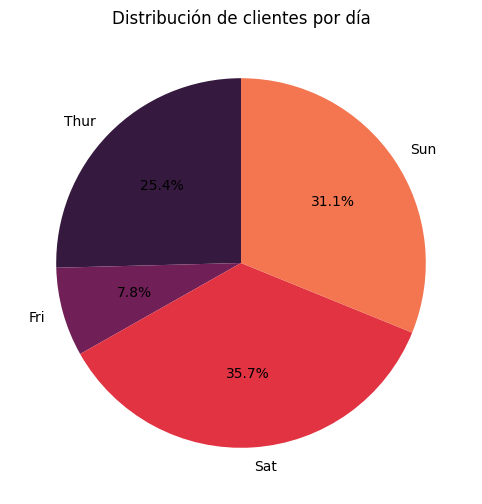

In [28]:
# PIE CHART

plt.figure(figsize=(8,6))
plt.pie(x='count', labels='day', data=df_1,
        autopct='%1.1f%%',
        startangle=90,
        colors=['#35193e', '#701f57', '#e13342', '#f37651'])
plt.title('Distribución de clientes por día')
plt.show()

**2. ¿Que dia de la semana tiene más mujeres que hombres como clientes?**

1. Preparación del dato
2. Visualización básica (matplotlib)
3. Customización

In [37]:
# PREPARACIÓN DEL DATO

df_2 = df.groupby(['day', 'sex'], as_index = False, observed = True)['total_bill'].count()
df_2

,day,sex,total_bill
0,Thur,Male,30
1,Thur,Female,32
2,Fri,Male,10
3,Fri,Female,9
4,Sat,Male,59
5,Sat,Female,28
6,Sun,Male,58
7,Sun,Female,18


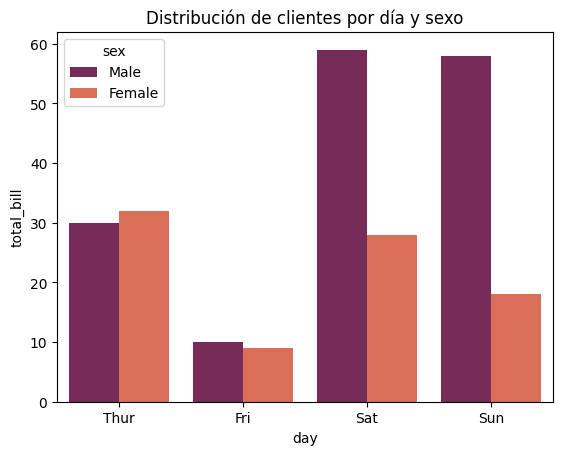

In [40]:
sns.barplot(data=df_2, x='day', y='total_bill', hue='sex', palette='rocket')
plt.title('Distribución de clientes por día y sexo')
plt.show()

Respuesta: El día de la semana que tiene más femeninas és el jueves

**3. ¿Crees que el hecho de ser fumador influye considerablemente en el total de la cuenta?**

In [44]:
df_groupby = df.groupby(['smoker'], as_index = False, observed = True)['total_bill'].describe()
df_groupby

,smoker,count,mean,std,min,25%,50%,75%,max
0,Yes,93.0,20.756344,9.832154,3.07,13.420,17.92,26.860,50.81
1,No,151.0,19.188278,8.255582,7.25,13.325,17.59,22.755,48.33


/tmp/ipython-input-2949698532.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='smoker', y='total_bill', palette='rocket', gap=0.1)


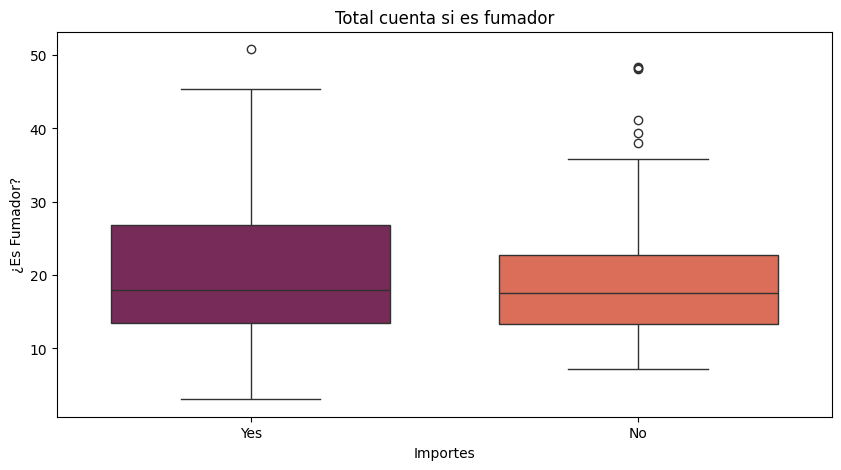

In [51]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='smoker', y='total_bill', palette='rocket', gap=0.1)
plt.title('Total cuenta si es fumador')
plt.xlabel('Importes')
plt.ylabel('¿Es Fumador?')
plt.show()

/tmp/ipython-input-4128246846.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='total_bill', y='smoker', palette='rocket', gap=0.1)


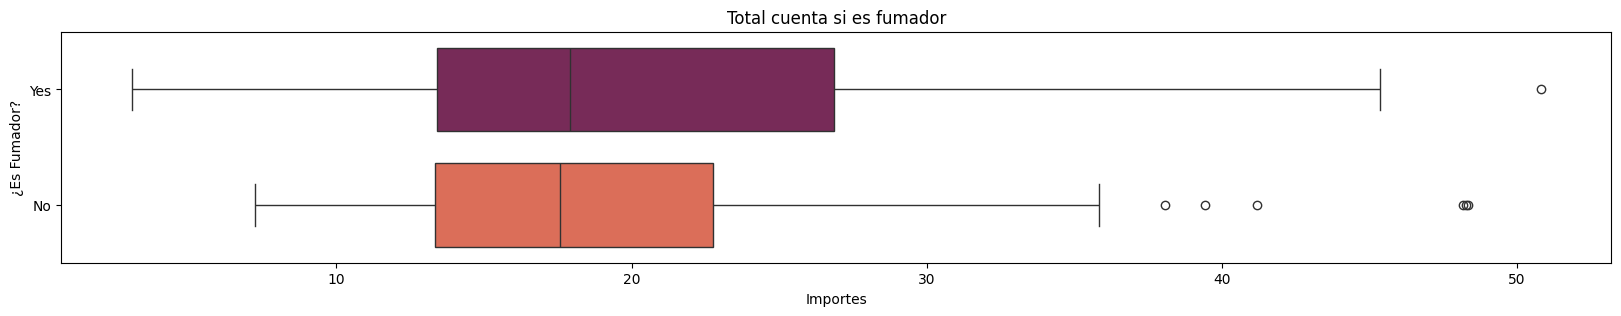

In [53]:
plt.figure(figsize=(20,3))
sns.boxplot(data=df, x='total_bill', y='smoker', palette='rocket', gap=0.1)
plt.title('Total cuenta si es fumador')
plt.xlabel('Importes')
plt.ylabel('¿Es Fumador?')
plt.show()

Respuesta: No vemos que sea significativo que fumar o no influye en la cuenta total.

**4. ¿Esta el total de la cuenta relacionado con la propina?**

In [55]:
# preparación de los datos // ver si estan corralcionadas.
df[['total_bill', 'tip']].corr()

,total_bill,tip
total_bill,1.000000,0.675734
tip,0.675734,1.000000


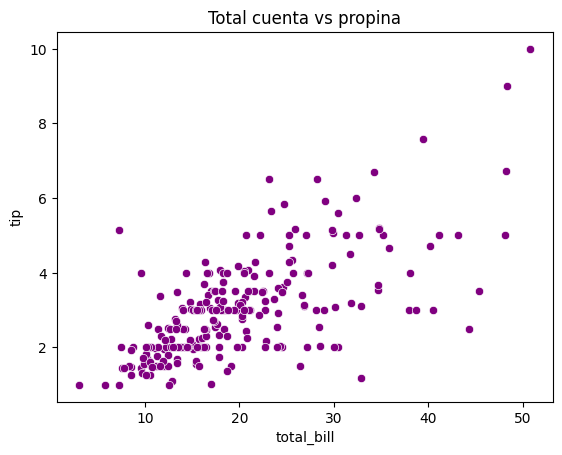

In [58]:
#scatterplot

sns.scatterplot(data=df, x = 'total_bill', y = 'tip', color = 'purple')
plt.title('Total cuenta vs propina')
plt.show()

Respuesta: Sí, es moderadamente significativa pero no al 100%. Es decir, cuanto mayor sea la cuenta mayor es la propina pero no siempre se da.

**5. ¿Como es esta correlación entre propina y cuenta en función de si es horario de comida o de cena?**

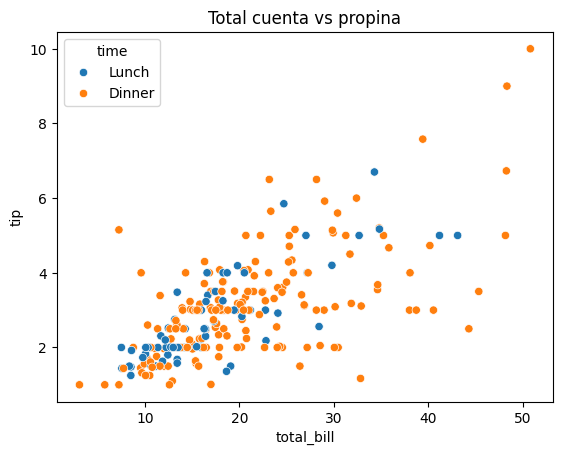

In [60]:
sns.scatterplot(data=df, x = 'total_bill', y = 'tip', hue = 'time')
plt.title('Total cuenta vs propina')
plt.show()

<Figure size 1500x600 with 0 Axes>

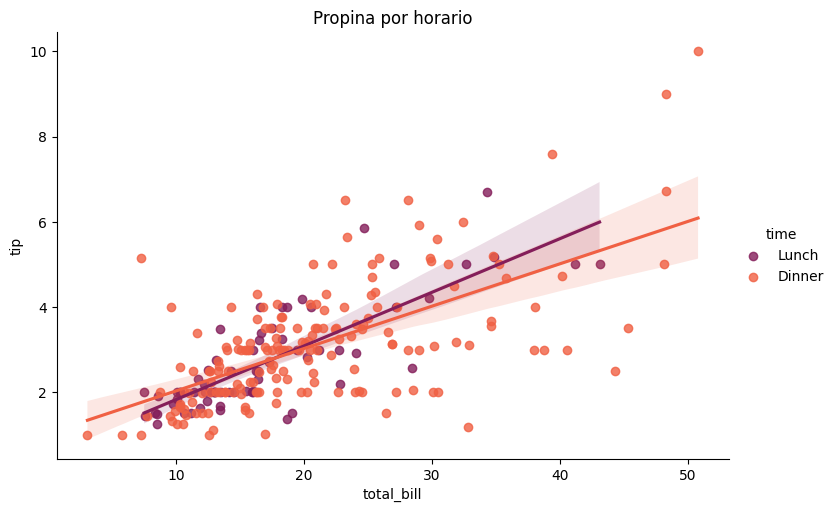

In [68]:
plt.figure(figsize=(15,6))
sns.lmplot(data= df, x='total_bill', y='tip', hue='time', palette='rocket',
          aspect =1.5,
          ci=95
           )
plt.title('Propina por horario')
plt.show()

Respuesta: Eligiría trabajar sábados y domingos a la hora de las cenas.

**BONUS**: Dibuja un gráfico a tu elección con 2 variables numéricas y 2 categóricas (SUGERENCIA: utiliza `hue` y `style`). ¿Te parece útil?

AttributeError: PathCollection.set() got an unexpected keyword argument 'aspect'

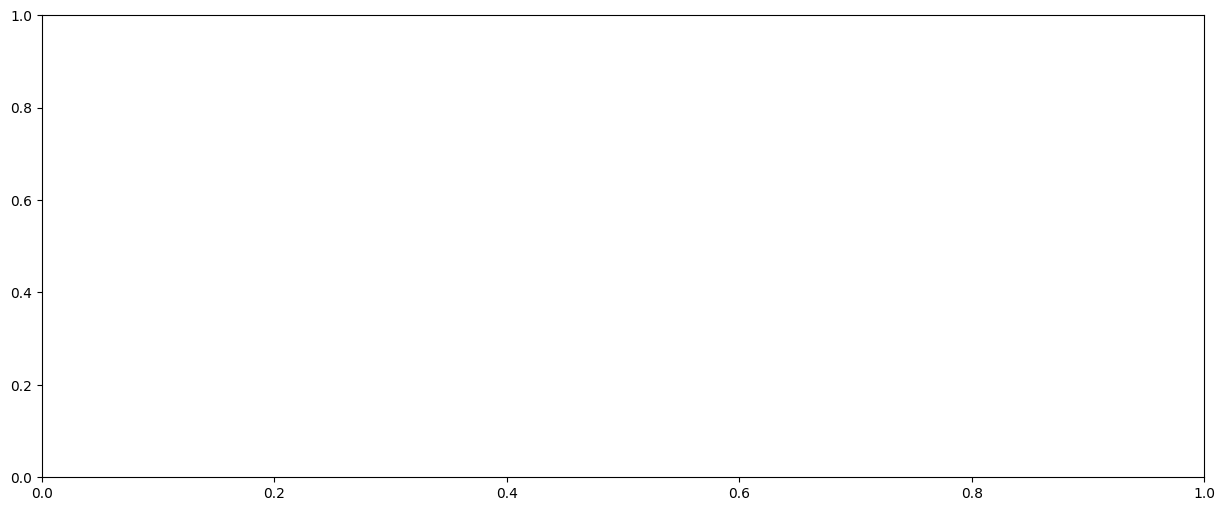

In [77]:
plt.figure(figsize=(15,6))
sns.scatterplot(data= df, x='total_bill', y='tip', hue='sex', style='day', palette='rocket',
          aspect =1.5,
          ci=95
           )
plt.title('Propina por sexo y si es fumador')
plt.show()

**En funcion de todos tus calculos:**

¿Qué día, en qué horario (cena o comida) y en qué zona del restaurante (fumadores no fumadores) elegirias trabajar?

Respuesta: